<a href="https://colab.research.google.com/github/Varpyx/Uro-Bootstrap/blob/main/fml_01_student_en_active_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fundamentals of Machine Learning — Project Part 1
## Základní zkoumání datasetu Spotify Songů
### Dataset dostupný zde: https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset


Nejdříve si vypíšu tvar, a zjistim info o datovych typech. Dale se podivame kolik hodnot missuje, a vypišeme si prvních 5 řádků.

In [9]:
import os
import pandas as pd
import kagglehub
import glob

# Stáhnutí nejnovější verze datasetu z Kaggle
path = kagglehub.dataset_download("yashdev01/spotify-tracks-dataset")

# Automatické nalezení libovolného CSV souboru ve stažené složce
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
if not csv_files:
    raise FileNotFoundError(f"V adresáři {path} nebyl nalezen žádný .csv soubor.")

# Načtení staženého CSV souboru
df = pd.read_csv(csv_files[0])

print(f"\nPočet řádků (skladeb): {df.shape[0]}")
print(f"Počet sloupců (vlastností): {df.shape[1]}\n")

df.info()

print("Chybějici hodnoty:\n")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Žádné chybějící hodnoty nebyly nalezeny.")

print("PRVNÍCH 5 ŘÁDKŮ")
df.head()

Using Colab cache for faster access to the 'spotify-tracks-dataset' dataset.

Počet řádků (skladeb): 114000
Počet sloupců (vlastností): 22

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 22 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0.1      114000 non-null  int64  
 1   Unnamed: 0        114000 non-null  int64  
 2   track_id          114000 non-null  object 
 3   artists           113999 non-null  object 
 4   album_name        113999 non-null  object 
 5   track_name        113999 non-null  object 
 6   popularity        114000 non-null  int64  
 7   duration_ms       114000 non-null  int64  
 8   explicit          114000 non-null  bool   
 9   danceability      114000 non-null  float64
 10  energy            114000 non-null  float64
 11  key               114000 non-null  int64  
 12  loudness          114000 non-null  float64
 13  mode              114000

,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


# Souhrn
Z vypisu dat vidime že unnamed colums jsou zde nejspíš stareé ID a nebudeme je tedy potřebovat.

Chybí nám 1 hodnota u artists, album_name a track_name. Tyto hodnoty nepoužijeme a smažeme

# Rozdělení sloupců:

## Metadata:
track_id, artists, album_name, track_name, track_genre

## Číselné příznaky (Audio Features):
danceability, energy, key, loudness, mode, speechiness, acousticness, instrumentalness, liveness, valence, tempo, duration_ms, popularity.

In [10]:
# 1. Odstranění zbytečných indexových sloupců
df_clean = df.drop(columns=["Unnamed: 0.1", "Unnamed: 0"])

# 2. Odstranění jednoho chybějícího řádku
df_clean = df_clean.dropna(subset=["artists", "album_name", "track_name"]).copy()

metadata_cols = ["track_id", "artists", "album_name", "track_name", "track_genre"]

feature_cols = [
    "danceability", "energy", "key", "loudness", "mode",
    "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo", "duration_ms", "popularity"
] #bereme v potaz i duration a popularity

# 4. Vytvoření samostatné matice pouze pro číselné příznaky
X = df_clean[feature_cols]

print(f"Počet řádků po vyčištění: {len(df_clean)}")
print(f"Počet vybraných číselných příznaků pro modelování: {X.shape[1]}")

Počet řádků po vyčištění: 113999
Počet vybraných číselných příznaků pro modelování: 13


## Nyní potřebujeme převést data na pomocí scaleru

$$z = \frac{x - \mu}{\sigma}$$

Střední hodnota (průměr) celého datasetu posune na 0:

* 0.0 = Písnička má v dané vlastnosti přesně průměrnou hodnotu celého datasetu.

* Kladné číslo (např. +1.8) = Písnička je v této vlastnosti nadprůměrná (např. má mnohem vyšší popularitu nebo tempo než většina skladeb).

* Záporné číslo (např. -2.3) = Písnička je v této vlastnosti výrazně podprůměrná.

In [11]:
from sklearn.preprocessing import StandardScaler

# 1. Přehled minim, maxim a průměrů před škálováním
print("=== PREHLED MĚŘÍTEK PŘED ŠKÁLOVÁNÍM ===")
display(X.describe().T[["min", "mean", "max", "std"]])

# 2. Aplikace StandardScaleru
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Převod výstupu (NumPy pole) zpět do Pandas DataFrame pro přehlednost
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)

print("\n=== NÁHLED NA VYŠKÁLOVANÁ DATA (prvních 5 řádků) ===")
display(X_scaled_df.head())

=== PREHLED MĚŘÍTEK PŘED ŠKÁLOVÁNÍM ===


,min,mean,max,std
danceability,0.000,0.566801,0.985,0.173543
energy,0.000,0.641383,1.000,0.251530
key,0.000,5.309126,11.000,3.559999
loudness,-49.531,-8.258950,4.532,5.029357
mode,0.000,0.637558,1.000,0.480708
speechiness,0.000,0.084652,0.965,0.105733
acousticness,0.000,0.314907,0.996,0.332522
instrumentalness,0.000,0.156051,1.000,0.309556
liveness,0.000,0.213554,1.000,0.190378
valence,0.000,0.474066,0.995,0.259261



=== NÁHLED NA VYŠKÁLOVANÁ DATA (prvních 5 řádků) ===


,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,popularity
0,0.629239,-0.717147,-1.210434,0.300825,-1.326297,0.551843,-0.850193,-0.504111,0.758735,0.929315,-1.141854,0.024557,1.782624
1,-0.845908,-1.889974,-1.210434,-1.784739,0.753979,-0.078995,1.831744,-0.504097,-0.591216,-0.798681,-1.489708,-0.730889,0.975625
2,-0.742187,-1.122667,-1.491334,-0.293289,0.753979,-0.273827,-0.315489,-0.504115,-0.507172,-1.365679,-1.528303,-0.160353,1.065291
3,-1.733301,-2.312987,-1.491334,-2.039246,0.753979,-0.457309,1.774605,-0.503886,-0.428381,-1.276965,1.987857,-0.243236,1.692957
4,0.295026,-0.788709,-0.929534,-0.282751,0.753979,-0.303146,0.463409,-0.504115,-0.686290,-1.184394,-0.073343,-0.271942,2.186123


## Shlukovaní

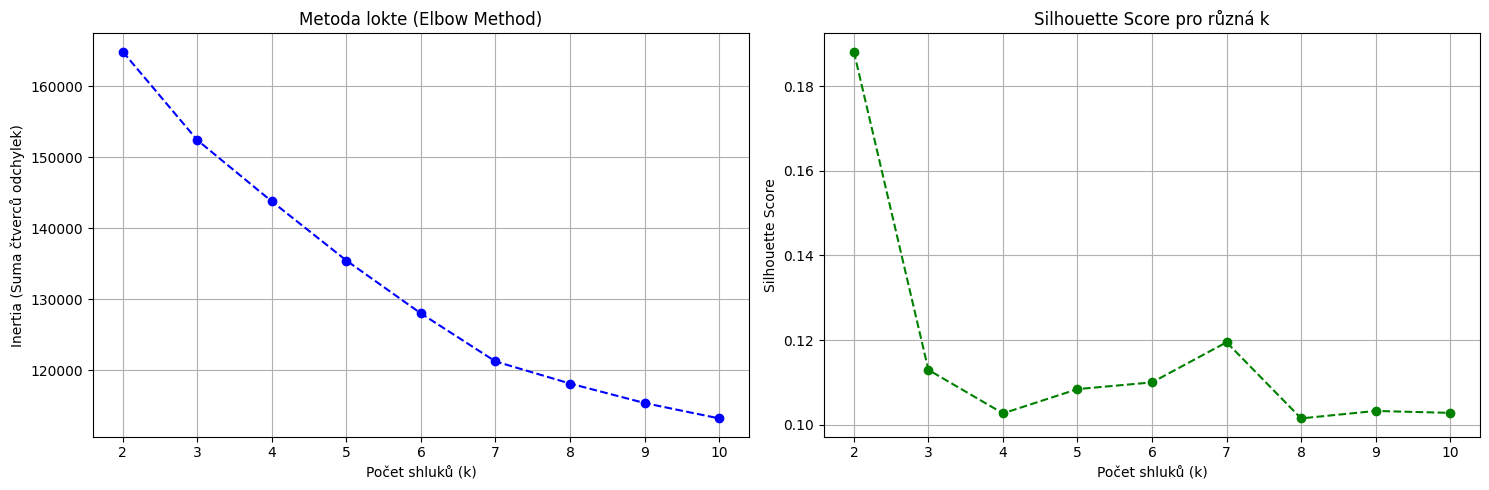

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Reprezentativní vzorek 15000 skladeb
np.random.seed(42)
sample_indices = np.random.choice(len(X_scaled), size=15000, replace=False)
X_sample = X_scaled[sample_indices]

inertia = []
silhouette_scores = []
k_range = range(2, 11)

# 2. Výpočet metrik
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto")
    labels = kmeans.fit_predict(X_sample)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_sample, labels))

# 3. Vykreslení obou grafů vedle sebe
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Graf 1: Metoda lokte (Elbow Plot)
ax1.plot(k_range, inertia, marker="o", linestyle="--", color="b")
ax1.set_xlabel("Počet shluků (k)")
ax1.set_ylabel("Inertia (Suma čtverců odchylek)")
ax1.set_title("Metoda lokte (Elbow Method)")
ax1.grid(True)

# Graf 2: Silhouette Score
ax2.plot(k_range, silhouette_scores, marker="o", linestyle="--", color="g")
ax2.set_xlabel("Počet shluků (k)")
ax2.set_ylabel("Silhouette Score")
ax2.set_title("Silhouette Score pro různá k")
ax2.grid(True)

plt.tight_layout()
plt.show()

Z dat vidime že neexistují izolované ostrůvky, protože skladby sdílejí mnoho podobností.

Celkové skoro Silhoutte je velmi nízke - vysoké překrytí.

Data lze tedy rozdělit buď na 2 nebo 7 skupin.

In [16]:
from sklearn.cluster import KMeans

# 1. Trénování K-means pro k = 2
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init="auto")
df_clean["cluster_k2"] = kmeans_2.fit_predict(X_scaled)

# 2. Trénování K-means pro k = 7
kmeans_7 = KMeans(n_clusters=7, random_state=42, n_init="auto")
df_clean["cluster_k7"] = kmeans_7.fit_predict(X_scaled)

# 3. Profil shluků pro k = 2 (průměrné hodnoty vlastností)
print("=== PROFIL SHLUKŮ PRO k = 2 ===")
display(df_clean.groupby("cluster_k2")[feature_cols].mean().T.round(2))

# 4. Profil shluků pro k = 7 (průměrné hodnoty vlastností)
print("\n=== PROFIL SHLUKŮ PRO k = 7 ===")
display(df_clean.groupby("cluster_k7")[feature_cols].mean().T.round(2))

=== PROFIL SHLUKŮ PRO k = 2 ===


cluster_k2,0,1
danceability,0.60,0.47
energy,0.75,0.31
key,5.42,4.98
loudness,-6.34,-14.09
mode,0.61,0.71
speechiness,0.09,0.06
acousticness,0.17,0.74
instrumentalness,0.11,0.30
liveness,0.22,0.18
valence,0.52,0.32



=== PROFIL SHLUKŮ PRO k = 7 ===


cluster_k7,0,1,2,3,4,5,6
danceability,0.57,0.53,0.35,0.62,0.58,0.60,0.58
energy,0.76,0.35,0.18,0.75,0.75,0.76,0.67
key,5.58,5.03,4.85,6.04,1.55,8.03,5.14
loudness,-8.33,-11.07,-21.13,-6.12,-6.15,-6.00,-10.87
mode,0.53,0.78,0.65,0.00,1.00,1.00,0.68
speechiness,0.07,0.05,0.05,0.10,0.08,0.08,0.80
acousticness,0.09,0.72,0.86,0.17,0.17,0.18,0.71
instrumentalness,0.77,0.04,0.79,0.03,0.03,0.02,0.01
liveness,0.19,0.18,0.17,0.22,0.24,0.22,0.63
valence,0.32,0.40,0.18,0.54,0.54,0.58,0.45


=== TOP 3 ŽÁNRY PRO KAŽDÝ SHLUK (k = 7) ===
Shluk 0: minimal-techno, detroit-techno, techno
Shluk 1: tango, honky-tonk, romance
Shluk 2: sleep, new-age, classical
Shluk 3: turkish, hip-hop, dancehall
Shluk 4: punk-rock, power-pop, sertanejo
Shluk 5: party, country, j-idol
Shluk 6: comedy, show-tunes, kids


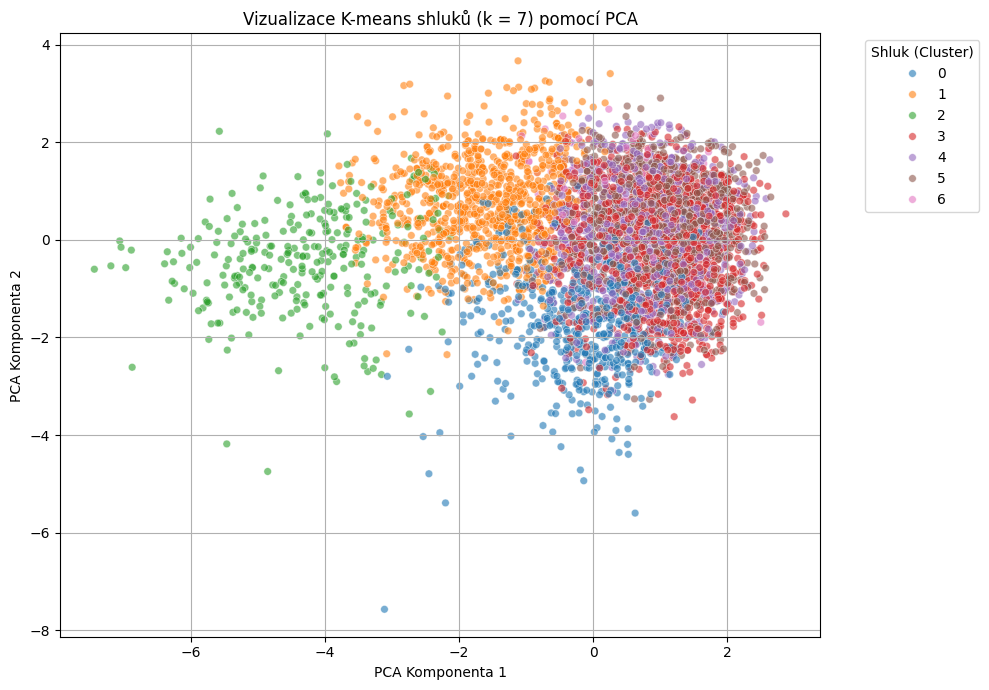

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Nejčastější žánry v jednotlivých shlucích pro k = 7
print("=== TOP 3 ŽÁNRY PRO KAŽDÝ SHLUK (k = 7) ===")
for cluster_id in range(7):
    top_genres = (
        df_clean[df_clean["cluster_k7"] == cluster_id]["track_genre"]
        .value_counts()
        .head(3)
        .index.tolist()
    )
    print(f"Shluk {cluster_id}: {', '.join(top_genres)}")

# 2. Redukce dimenzionality pomocí PCA na 2 komponenty
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Pro rychlou a přehlednou vizualizaci použijeme vzorek 5 000 bodů
np.random.seed(42)
vis_indices = np.random.choice(len(X_pca), size=5000, replace=False)

# 3. Vykreslení 2D grafu shluků pro k = 7
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[vis_indices, 0],
    y=X_pca[vis_indices, 1],
    hue=df_clean.iloc[vis_indices]["cluster_k7"],
    palette="tab10",
    alpha=0.6,
    s=30,
)
plt.title("Vizualizace K-means shluků (k = 7) pomocí PCA")
plt.xlabel("PCA Komponenta 1")
plt.ylabel("PCA Komponenta 2")
plt.legend(title="Shluk (Cluster)", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

## Výpis žánrů

Model K-means při shlukování vůbec neviděl názvy žánrů, přesto podle těchto akustických vlastností dokázal sám přirozeně poskládat příbuzné žánry k sobě:

* Shluk 0: Čistě elektronická/techno hudba (vysoká rytmičnost a instrumentalita).

* Shluk 2: Relaxační hudba, klasika a spánek (vysoká akustičnost, velmi nízká energie).

* Shluk 6: Mluvené slovo, komedie a dětské pořady (vysoký podíl řeči / speechiness).

# PCA Graf
PCA zmáčkl těchto 13 proměnných do 2 hlavních směrů (PCA Komponenta 1 a 2):

* Vodorovná osa (PCA 1): Odděluje klidnou hudbu od tvrdé/energické. Zelené body (Shluk 2 – spánek/klasika) leží úplně vlevo, protože mají extrémně nízkou energii. Směrem doprava energie a hlasitost roste.

* Svislá osa (PCA 2): Odděluje specifické rytmické a zvukové struktury (např. modrý Shluk 0 dole reprezentuje techno s jasným elektronickým beatem).

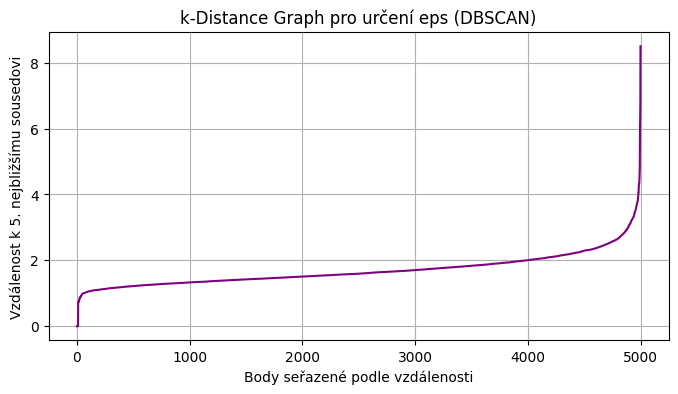

In [18]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

# Pro rychlý výpočet k-NN použijeme vzorek 5 000 skladeb
np.random.seed(42)
sample_indices = np.random.choice(len(X_scaled), size=5000, replace=False)
X_sample_db = X_scaled[sample_indices]

# Spočítej vzdálenost k 5. nejbližšímu sousedovi pro každý bod
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_sample_db)
distances, _ = neighbors_fit.kneighbors(X_sample_db)

# Seřaď vzdálenosti od nejmenší po největší
distances = np.sort(distances[:, 4], axis=0)

# Vykreslení grafu
plt.figure(figsize=(8, 4))
plt.plot(distances, color="purple")
plt.title("k-Distance Graph pro určení eps (DBSCAN)")
plt.xlabel("Body seřazené podle vzdálenosti")
plt.ylabel("Vzdálenost k 5. nejbližšímu sousedovi")
plt.grid(True)
plt.show()

Na grafu je zlomový bod (koleno křivky) pěkně vidět. Vzdálenost začíná znatelně stoupat okolo hodnoty eps = 2,0 až 2,3 (před x = 4800, než křivka vystřelí kolmo nahoru).   

Zvolíme tedy eps = 2.0 a min_samples = 5 a spustíme DBSCAN na připraveném vzorku.

In [19]:
from sklearn.cluster import DBSCAN
import numpy as np

# 1. Spuštění DBSCAN s eps = 2.0 a min_samples = 5
dbscan = DBSCAN(eps=2.0, min_samples=5)
db_labels = dbscan.fit_predict(X_sample_db)

# 2. Vyhodnocení výsledků
unique_labels, counts = np.unique(db_labels, return_counts=True)
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = np.sum(db_labels == -1)

print("=== VÝSLEDKY DBSCAN (eps = 2.0) ===")
print(f"Počet nalezených shluků: {n_clusters}")
print(f"Počet bodů označených jako šum (-1): {n_noise} ({(n_noise / len(db_labels)) * 100:.1f} %)")
print("\nRozdělení bodů do jednotlivých shluků:")
for label, count in zip(unique_labels, counts):
    name = "Šum (-1)" if label == -1 else f"Shluk {label}"
    print(f"  {name}: {count} skladeb")

=== VÝSLEDKY DBSCAN (eps = 2.0) ===
Počet nalezených shluků: 7
Počet bodů označených jako šum (-1): 529 (10.6 %)

Rozdělení bodů do jednotlivých shluků:
  Šum (-1): 529 skladeb
  Shluk 0: 2907 skladeb
  Shluk 1: 1526 skladeb
  Shluk 2: 14 skladeb
  Shluk 3: 5 skladeb
  Shluk 4: 5 skladeb
  Shluk 5: 10 skladeb
  Shluk 6: 4 skladeb


Z rozdělení pomocí DBSCAN jsme zjistili, že našel 6 skupin a šum. Avšak většinu skladeb přiřadíme do Shluku 0 nebo 1, dalo by se tedy mluvit spíš o dvou skupinách.

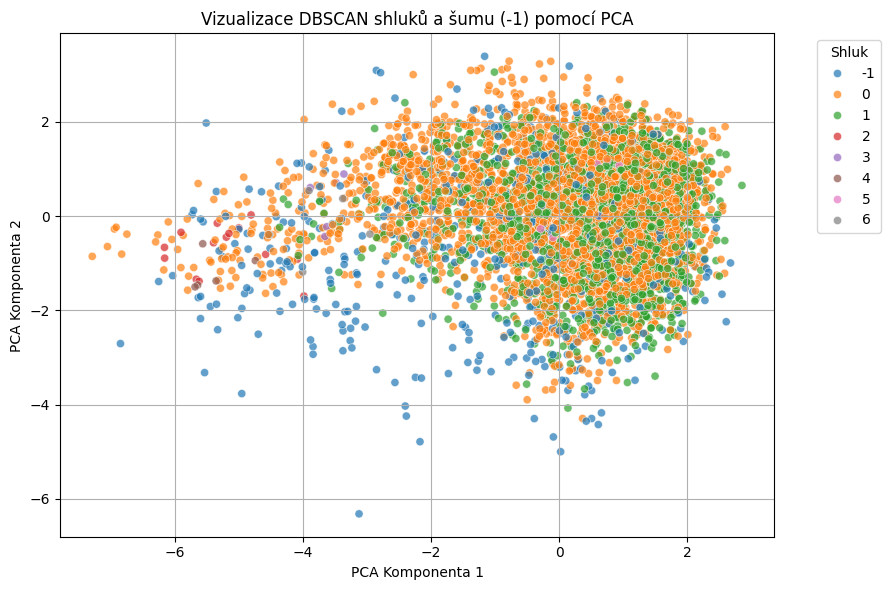

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Redukce dimenzionality vzorku DBSCANu na 2 komponenty
pca_db = PCA(n_components=2, random_state=42)
X_sample_pca = pca_db.fit_transform(X_sample_db)

# 2. Vykreslení grafu
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=X_sample_pca[:, 0],
    y=X_sample_pca[:, 1],
    hue=db_labels,
    palette="tab10",
    alpha=0.7,
    s=35,
)
plt.title("Vizualizace DBSCAN shluků a šumu (-1) pomocí PCA")
plt.xlabel("PCA Komponenta 1")
plt.ylabel("PCA Komponenta 2")
plt.legend(title="Shluk", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

# Finální srovnání našich zjistění s realitou

In [21]:
# 1. Počet unikátních žánrů v datasetu
num_genres = df_clean["track_genre"].nunique()
all_genres = df_clean["track_genre"].unique()

print(f"Celkový počet unikátních žánrů v datasetu: {num_genres}")
print("\nUkázka žánrů (prvních 20):")
print(list(all_genres[:20]))

Celkový počet unikátních žánrů v datasetu: 114

Ukázka žánrů (prvních 20):
['acoustic', 'afrobeat', 'alt-rock', 'alternative', 'ambient', 'anime', 'black-metal', 'bluegrass', 'blues', 'brazil', 'breakbeat', 'british', 'cantopop', 'chicago-house', 'children', 'chill', 'classical', 'club', 'comedy', 'country']


* Počet původních žánrů: Dataset obsahuje 114 unikátních žánrových štítků (track_genre).

* Naše shlukování: Pomocí algoritmu K-means jsme data rozdělili do $k = 7$ shluků.



Třídění do 114 žánrů v reálném světě spoléhá na historické, kulturní a textové kontexty (např. rozlišení mezi minimal-techno, detroit-techno a techno). S

amotné akustické proměnné (tempo, energie, hlasitost) nemají dostatek informací pro odlišení takto detailních podžánrů.

Shlukování proběhlo nečekaně úspěšně na úrovni nadřazených kategorií.

Všechny elektronické podžánry (techno, minimal-techno, detroit-techno) se spojily do Shluku 0.

Všechny klidné/akustické žánry (classical, sleep, new-age) se shlukly do Shluku 2.

Mluvené slovo a dětské pořady (comedy, kids) skončily samostatně v Shluku 6.

## Závěr:
Model bez jakéhokoliv předchozího vědomí o žánrech (Unsupervised Learning) dokázal z pouhých číselných audio vlastností rekonstruovat základní hudební strukturu a zredukoval 114 mikro-žánrů do 7 logických, lidsky interpretovatelných akustických skupin.